Cells are chemistry. DNA is a molecule, proteins are molecules, a drug is a molecule that sticks to a protein. This chapter teaches the handful of chemical ideas you need for the rest of the course: what atoms and bonds are, why water matters so much, what pH is, how molecules stick to each other, and how energy decides which reactions happen.

:::eli5
Atoms are Lego bricks. A few kinds (mostly carbon, hydrogen, oxygen and nitrogen) click together into molecules. Small molecules click together in long chains to make the big molecules of life: sugars make starch, amino acids make proteins, nucleotides make DNA. Molecules also stick to each other loosely, like magnets, and that loose sticking is how almost everything in a cell happens, including how a drug finds its target.
:::

## Atoms: the elements of life

An atom has a tiny, heavy **nucleus** (protons and neutrons) surrounded by **electrons**. The number of protons defines the element. Chemistry is entirely about what the outer electrons do.

Six elements make up about 98% of living matter: **C**arbon, **H**ydrogen, **O**xygen, **N**itrogen, **P**hosphorus and **S**ulfur ("CHONPS").

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from pathlib import Path

mpl.rc("figure", dpi=110); mpl.rc("axes", labelsize=12, titlesize=13)
IMAGES = Path("images"); IMAGES.mkdir(exist_ok=True)
def save_fig(name):
    plt.tight_layout(); plt.savefig(IMAGES / f"{name}.png", dpi=150, bbox_inches="tight")
R = {}

# approximate elemental composition of the human body by mass (%)
body = {"O": 65.0, "C": 18.5, "H": 9.5, "N": 3.2, "Ca": 1.5, "P": 1.0, "K": 0.4, "S": 0.3, "Na": 0.2, "Cl": 0.2, "Mg": 0.1, "others": 0.1}
bonds = {"H": 1, "O": 2, "N": 3, "C": 4, "P": 5, "S": 2}          # how many covalent bonds each usually forms
for el, pct in body.items():
    extra = f"  forms {bonds[el]} bond(s)" if el in bonds else ""
    print(f"{el:7s} {pct:5.1f}% of body mass{extra}")

O        65.0% of body mass  forms 2 bond(s)
C        18.5% of body mass  forms 4 bond(s)
H         9.5% of body mass  forms 1 bond(s)
N         3.2% of body mass  forms 3 bond(s)
Ca        1.5% of body mass
P         1.0% of body mass  forms 5 bond(s)
K         0.4% of body mass
S         0.3% of body mass  forms 2 bond(s)
Na        0.2% of body mass
Cl        0.2% of body mass
Mg        0.1% of body mass
others    0.1% of body mass


Oxygen tops the list by mass mainly because you are mostly water. **Carbon** is the backbone of life because it forms **four** bonds, so it can build chains, rings and branches of almost endless variety. That is the basis of "organic" chemistry.

## Bonds: strong and weak

| Bond | What it is | Strength (kJ/mol) | Role in biology |
|---|---|---|---|
| **Covalent** | two atoms *share* electrons | ~350 | holds each molecule together: the DNA backbone, protein chains |
| **Ionic** | a + charged and a − charged group attract | ~5–20 in water | salt bridges inside proteins; DNA (negative) binding proteins (positive) |
| **Hydrogen bond** | an H on O or N is attracted to another O or N | ~5–20 | holds the two DNA strands together; shapes proteins; drug binding |
| **Van der Waals** | brief attraction between any nearby atoms | ~1–4 each | tight packing inside proteins and drug pockets |
| **Hydrophobic effect** | oily parts are pushed together by water | — | folds proteins, forms membranes, drives most drug binding |

The key insight: **covalent bonds build molecules, weak bonds make molecules interact.** Weak bonds are individually feeble and constantly breaking and re-forming at body temperature. But many of them together, in exactly the right geometry, give strong and very specific binding. A drug binds its target, and not the other 20,000 proteins, because dozens of weak contacts fit just right, like a key in a lock.

## Water: the medium of life

Water (H₂O) is **polar**: oxygen pulls electrons towards itself, so the O end is slightly negative and the H ends slightly positive. This gives water its special powers:

- It forms **hydrogen bonds** with itself and with other polar molecules, so it dissolves sugars, salts, amino acids and DNA (*hydrophilic*, "water-loving", molecules).
- It **does not** mix with oils and fats (*hydrophobic*, "water-fearing"). Water molecules prefer bonding to each other, so they push oily molecules together.

That **hydrophobic effect** is one of the most important forces in biology: it makes cell membranes assemble by themselves, it folds proteins (oily amino acids hide inside), and it is the main driving force for most drug binding (oily parts of a drug tuck into oily pockets of a protein).

## Acids, bases and pH

Some molecules release hydrogen ions (H⁺, a bare proton) into water: these are **acids**. **Bases** take H⁺ up. The **pH** measures how many free H⁺ ions there are:

:::math
$$\text{pH} = -\log_{10}[\text{H}^+]$$

where $[\text{H}^+]$ is the concentration in moles per litre. pH 7 (neutral) means $[\text{H}^+] = 10^{-7}$ M. Because of the logarithm, **each unit is a 10-fold change**.

A chemical group that can gain or lose a proton has a $\text{p}K_a$: the pH at which it is half protonated. The **Henderson–Hasselbalch** equation gives the charged fraction:

$$\text{fraction deprotonated} = \frac{1}{1 + 10^{\,\text{p}K_a - \text{pH}}}.$$
:::

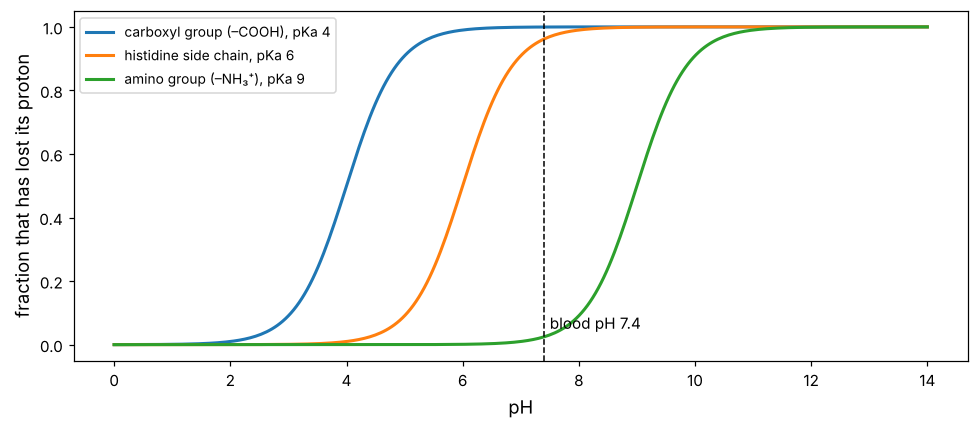

In [2]:
pH = np.linspace(0, 14, 300)
groups = {"carboxyl group (–COOH), pKa 4": 4.0, "histidine side chain, pKa 6": 6.0, "amino group (–NH₃⁺), pKa 9": 9.0}
fig, ax = plt.subplots(figsize=(9, 4))
for name, pka in groups.items():
    ax.plot(pH, 1 / (1 + 10 ** (pka - pH)), lw=2, label=name)
ax.axvline(7.4, color="k", ls="--", lw=1); ax.text(7.5, 0.05, "blood pH 7.4")
ax.set_xlabel("pH"); ax.set_ylabel("fraction that has lost its proton"); ax.legend(fontsize=9)
save_fig("henderson"); plt.show()
R["his_frac"] = f"{1 / (1 + 10 ** (6.0 - 7.4)):.0%}"

![Figure P2-1. How acidic groups lose their protons as pH rises. At pH 7.4, carboxyl groups are negatively charged and amino groups positively charged.](images/henderson.png)

At blood pH, a carboxyl group is negatively charged (it has lost H⁺), an amino group is positively charged, and a histidine side chain is in between (96% deprotonated). This is why amino acids in proteins carry charges, why DNA (full of phosphate groups) is strongly negative, and why a drug's charge state, which depends on pH, decides whether it can cross an oily cell membrane.

## The four families of biological molecules

Life builds big molecules (**macromolecules**) by linking small units (**monomers**) into chains (**polymers**):

| Family | Building block | Polymer examples | Main jobs |
|---|---|---|---|
| **Carbohydrates** | sugars (glucose) | starch, glycogen, cellulose | fuel, energy storage, structure, cell-surface labels |
| **Lipids** | fatty acids, glycerol | fats, phospholipids, cholesterol, steroid hormones | membranes, energy storage, signals |
| **Proteins** | 20 amino acids | enzymes, antibodies, receptors, collagen | almost all the work (chapter P5) |
| **Nucleic acids** | 4 nucleotides | DNA, RNA | storing and transmitting information (P3, P4) |

Lipids are not true polymers, but they assemble spontaneously into large structures. **Phospholipids** have a water-loving head and two oily tails. In water they arrange themselves into a **bilayer**, heads out and tails in. That is the cell membrane: about 5 nm thick, self-assembling, and impermeable to charged and large molecules. Most drugs must cross it, which is why drug chemists care so much about "lipophilicity" (chapter 13).

## Binding: how molecules recognise each other

Biology runs on molecules binding to each other: a hormone to its receptor, a transcription factor to DNA, an antibody to a virus, a drug to an enzyme. One number describes how tightly two molecules bind, the **dissociation constant** $K_d$.

:::math
For a target $P$ and a ligand $L$ that bind reversibly, $P + L \rightleftharpoons PL$, the equilibrium is described by

$$K_d = \frac{[P][L]}{[PL]}.$$

Rearranging, the fraction of target that is bound is

$$\theta = \frac{[L]}{[L] + K_d}.$$

When $[L] = K_d$, exactly half the target is bound. A **smaller** $K_d$ means **tighter** binding. Typical values: weak, millimolar (mM); good drugs, nanomolar (nM, $10^{-9}$ M); antibodies, picomolar (pM).
:::

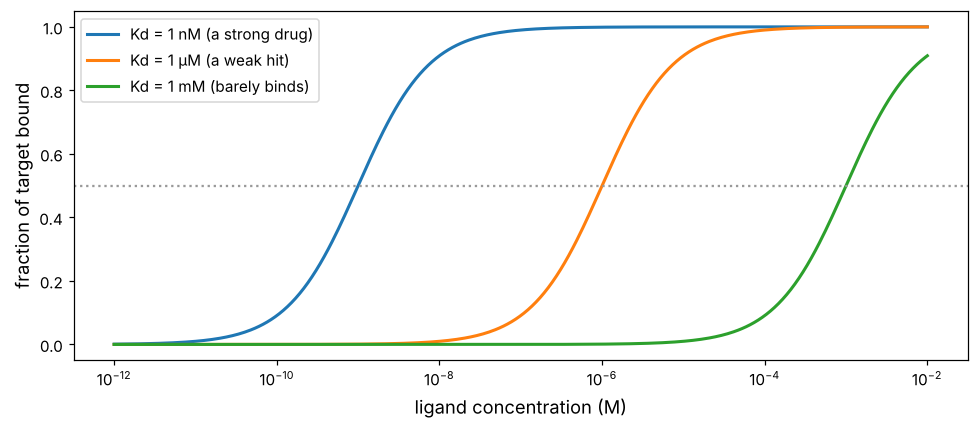

In [3]:
L = np.logspace(-12, -2, 400)                       # ligand concentration, M
fig, ax = plt.subplots(figsize=(9, 4))
for kd, lab in [(1e-9, "Kd = 1 nM (a strong drug)"), (1e-6, "Kd = 1 µM (a weak hit)"), (1e-3, "Kd = 1 mM (barely binds)")]:
    ax.semilogx(L, L / (L + kd), lw=2, label=lab)
ax.axhline(0.5, color="0.6", ls=":"); ax.set_xlabel("ligand concentration (M)"); ax.set_ylabel("fraction of target bound")
ax.legend(); save_fig("binding"); plt.show()
conc = 1e-8
R["occ_nm"] = f"{conc / (conc + 1e-9):.0%}"; R["occ_um"] = f"{conc / (conc + 1e-6):.1%}"

![Figure P2-2. Binding curves for ligands with different affinities. Each curve rises from 0 to 1 over about two orders of magnitude of concentration, and is half-way up at its Kd.](images/binding.png)

At 10 nM, a 1 nM binder occupies 91% of its target but a 1 µM binder only 1.0%. Improving affinity is a central goal of drug design, and **Kd** (or the related IC50, chapter P13) is the number on which medicinal chemists judge their molecules.

## Energy: which reactions happen?

Whether a reaction or binding event happens on its own is decided by the change in **Gibbs free energy**, ΔG. Negative ΔG means it can proceed spontaneously.

:::math
ΔG combines energy and disorder: $\Delta G = \Delta H - T\Delta S$. Here $\Delta H$ is heat released or absorbed (bonds formed or broken) and $\Delta S$ is the change in disorder (entropy).

ΔG and the equilibrium constant are directly linked:

$$\Delta G^\circ = -RT\ln K,$$

with $R = 8.314$ J/(mol·K) and $T$ in kelvin. For binding, $K = 1/K_d$. At body temperature, $RT\ln 10 \approx 5.9$ kJ/mol, so **every 5.9 kJ/mol of extra binding energy makes binding 10 times tighter.** One good hydrogen bond is worth a few kJ/mol.
:::

In [4]:
RT = 8.314e-3 * 310.15                               # kJ/mol at 37 °C
for kd in [1e-3, 1e-6, 1e-9, 1e-12]:
    dG = RT * np.log(kd)                             # ΔG of binding = -RT ln(1/Kd) = RT ln Kd
    print(f"Kd = {kd:.0e} M  ->  ΔG of binding = {dG:6.1f} kJ/mol")
R["dg_nM"] = f"{RT * np.log(1e-9):.0f}"

Kd = 1e-03 M  ->  ΔG of binding =  -17.8 kJ/mol
Kd = 1e-06 M  ->  ΔG of binding =  -35.6 kJ/mol
Kd = 1e-09 M  ->  ΔG of binding =  -53.4 kJ/mol
Kd = 1e-12 M  ->  ΔG of binding =  -71.2 kJ/mol


A nanomolar drug binds with about -53 kJ/mol: roughly the energy of a dozen good weak contacts, but less than a fifth of one covalent bond. Most drugs bind *reversibly* through weak bonds; a few (such as aspirin and some modern cancer drugs) form a covalent bond with their target.

### ATP: the energy currency

Many reactions a cell needs have positive ΔG and won't happen alone: building proteins, pumping ions, moving muscles. Cells **couple** them to a strongly favourable reaction: breaking **ATP** (adenosine triphosphate) into ADP and phosphate, which releases about 30–50 kJ/mol under cellular conditions. You turn over roughly your own body weight in ATP every day, regenerating it in mitochondria from the food you eat (chapter P9).

### Enzymes speed things up, but don't change ΔG

Even favourable reactions can be extremely slow, because molecules must pass through a high-energy **transition state**. **Enzymes** (protein catalysts, chapter P5) lower that barrier, often speeding reactions up a million-fold or more, without changing where the equilibrium lies. Many drugs are enzyme inhibitors.

## Try it

The playground has three parts: binding curves for two drugs with adjustable Kd, an interactive pH scale with biological examples, and an equilibrium simulator linking ΔG to how many molecules end up in each state.

::playground animations/chem_lab.html 600

:::check
1. A drug has Kd = 100 nM. At what concentration is half its target bound? *(100 nM.)*
2. pH drops from 7 to 5. How many times more H⁺ is there? *(100 times.)*
3. Why do phospholipids form a bilayer in water? *(Their oily tails avoid water: the hydrophobic effect pushes tails together and leaves the polar heads facing water.)*
4. Binding energy improves by 11.8 kJ/mol. By how much does Kd change? *(About 100-fold tighter: two factors of 10.)*
:::

:::exercise
A cell has 10,000 copies of a receptor. A hormone binds it with Kd = 2 nM. Write a function that returns the number of occupied receptors at a given hormone concentration, and find the concentration needed to occupy 9,000 receptors.
:::

<details><summary>Solution</summary>

In [5]:
def occupied(L, kd=2e-9, total=10_000):
    return total * L / (L + kd)

# solve 0.9 = L / (L + Kd)  ->  L = 9 * Kd
L90 = 9 * 2e-9
print(f"{occupied(L90):.0f} receptors occupied at {L90 * 1e9:.0f} nM")

9000 receptors occupied at 18 nM


You need 9 × Kd = 18 nM. In general, going from 50% to 90% occupancy takes 9 times more ligand, and 99% takes 99 times more. This is why drugs are often dosed well above their Kd.

</details>